# RAG pour la sécurité des machines industrielles
**Question-réponse sur une collection documentaire spécialisée**
Auteur : Mohamed Ghandour

> **Note de transparence.** Ce projet a été réalisé avec l'assistance de **Claude Code** (Anthropic) pour le code des modules `src/`, les brouillons de questions du jeu de test et une première version de ce notebook. Les annotations utilisées pour valider le juge LLM ont été produites par Claude, non par un humain (voir §6). Le jeu de test n'a pas été relu intégralement à la main : les résultats sont **préliminaires** (voir §9).

## 1. Introduction et problématique

Un grand modèle de langage (LLM) répond de mémoire. Dans un domaine réglementaire et technique comme la **sécurité des machines**, cela pose deux problèmes : il peut **inventer** une valeur, un seuil ou un article de loi qui paraît plausible, et il ne peut pas **citer sa source**. Une erreur sur une distance de sécurité ou une fréquence de vérification n'est pas anodine.

**Le RAG (Retrieval-Augmented Generation)** répond à ce problème en deux temps : (1) *retrouver* dans un corpus les passages pertinents, (2) *générer* la réponse en s'appuyant uniquement sur ces passages, avec citation des sources et possibilité de s'abstenir.

**Problématique.** *Sur un corpus de documents français sur la sécurité des machines (brochures INRS, règlement UE 2023/1230, directive 2006/42/CE), quelle chaîne de recherche et de génération donne les réponses les plus exactes, les mieux sourcées et les moins hallucinées, et à quel coût ?*

Quatre systèmes sont définis : **S0** (LLM seul, baseline), **S1** (BM25 + LLM), **S2** (embeddings denses + LLM), **S3** (hybride + reranker + LLM). Les quatre sont comparés en **retrieval** ; en **génération**, seuls S0 et S1 ont pu être évalués (quota d'API, voir §9). Le sujet a aussi un lien direct avec mon stage en ML industriel chez SAMM Automation.

## 2. Bref état de l'art

- **RAG** : Lewis et al. (2020) proposent d'augmenter un générateur par un module de recherche pour réduire les hallucinations et rendre les réponses traçables.
- **Recherche lexicale, BM25** : Robertson & Zaragoza (2009). Un classique robuste, souvent difficile à battre sur des termes techniques.
- **Recherche dense** : des encodeurs transforment textes et requêtes en vecteurs ; ici **bge-m3** (Chen et al., 2024), multilingue et à contexte long.
- **Hybride et fusion** : combiner lexical et dense par *Reciprocal Rank Fusion* (Cormack et al., 2009).
- **Reranking** : un *cross-encoder* relit chaque couple (question, passage) ; ici **bge-reranker-v2-m3**.
- **Évaluation par LLM-juge** : Zheng et al. (2023) (*MT-Bench / LLM-as-a-judge*), avec des biais connus (préférence pour ses propres sorties, pour les réponses longues).

## 3. Données et préparation

**Corpus** : 40 documents, 1 516 pages — 38 brochures INRS et 2 textes de l'UE (règlement 2023/1230, directive 2006/42/CE). Sources dans `data/sources.csv`. Les PDF ne sont pas versionnés (`data/raw/`).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.width", 160, "display.max_colwidth", 90)

src = pd.read_csv(ROOT / "data/sources.csv")
print(len(src), "documents,", src.pages.sum(), "pages")
src.assign(organisme=src.fichier.str.startswith("EURLEX").map({True: "EUR-Lex", False: "INRS"})).groupby("organisme").agg(documents=("fichier", "count"), pages=("pages", "sum"))

40 documents, 1516 pages


,documents,pages
organisme,,
EUR-Lex,2,165
INRS,38,1351


### 3.1 Extraction du texte

J'ai comparé deux bibliothèques sur des pages réelles : **pymupdf** (rapide, bon ordre de lecture, casse des sigles conservée) et **pdfplumber** (meilleur sur les tableaux). Aucune ne gagne partout, d'où une **extraction hybride** (`src/extract.py`) :
- texte courant : pymupdf ; tableaux : pdfplumber, réécrits « colonne : valeur » pour que chaque ligne garde ses en-têtes ;
- titres repérés par la taille de police (INRS) ou par le motif « Article / CHAPITRE / ANNEXE » (EUR-Lex) ;
- nettoyage : en-têtes et pieds de page répétés, césures résolues avec un vocabulaire du corpus (« at-traction » → « attraction », mais « main-bras » conservé), puces Wingdings, caractères parasites, cases à cocher.

**Limite** : les figures et pictogrammes ne sont pas extraits, seulement leurs légendes.

In [2]:
d = json.load(open(ROOT / "data/processed/text/INRS_ED828.json", encoding="utf-8"))
print(d["pages"][13]["text"][:900])

1.2. LOCAL À POLLUTION SPÉCIFIQUE
1-2-A > Quand l’air n’est pas recyclé
Objet de la vérification : Débit global d’air extrait | Type de vérification : Contrôle | Moment ou fréquence de la vérification : Annuel | Personne ou organisme chargé de la vérification : Personne compétente (cf. chapitre 1 : « Modalités de réalisation des vérifications périodiques/ Qui effectue les vérifications ? ») | Documents complétés ou établis, si nécessaire, à la suite de la vérification : Mise à jour du dossier des valeurs de référence contenu dans la notice d’instructions (établi au plus tard un mois après la mise en service pour chaque installation nouvelle ou lors du premier contrôle périodique pour chaque installation existante) + Mise à jour du dossier de maintenance contenu dans la consigne d’utilisation | Textes de référence : Arr. 08.10.1987, art. 4
Objet de la vérification : État des éléments de l


### 3.2 Découpage en chunks (*chunking*)

On ne peut pas donner 1 500 pages à un LLM ni chercher efficacement dans de gros blocs : on découpe en **chunks**. Deux stratégies sont comparées, sur le **même texte nettoyé** :
- **fixe** : fenêtre glissante de N tokens avec 15 % de recouvrement, sans égard à la structure (baseline) ;
- **structurel** : on ne traverse jamais un titre ; les paragraphes sont regroupés jusqu'à N tokens ; une ligne de tableau n'est jamais coupée ; chaque chunk reçoit un fil d'Ariane (« Règlement 2023/1230 > CHAPITRE V > Article 32 »).

Trois tailles : 256, 512, 1024 tokens (comptés avec le tokenizer de bge-m3). Le contexte est compté **dans** le budget pour que la comparaison soit équitable.

In [3]:
rows = []
for strat in ("fixed", "structural"):
    for size in (256, 512, 1024):
        ch = [json.loads(l) for l in open(ROOT / f"data/processed/chunks/{strat}_{size}.jsonl", encoding="utf-8")]
        t = pd.Series([c["n_tokens"] for c in ch])
        rows.append({"stratégie": strat, "taille": size, "chunks": len(ch), "tokens moyens": round(t.mean()), "max": t.max()})
pd.DataFrame(rows)

,stratégie,taille,chunks,tokens moyens,max
0,fixed,256,4072,251,254
1,fixed,512,1971,503,510
2,fixed,1024,976,1000,1022
3,structural,256,4625,208,255
4,structural,512,2220,397,507
5,structural,1024,1330,641,1014


In [4]:
ch = [json.loads(l) for l in open(ROOT / "data/processed/chunks/structural_512.jsonl", encoding="utf-8")]
c = next(c for c in ch if c["doc"].startswith("EURLEX_reglement") and "Article 32" in c["section"])
print("[contexte]", c["context"]); print(c["text"][:500])

[contexte] Règlement (UE) 2023/1230 du Parlement européen et du Conseil du 14 juin 2023 sur les machines > CHAPITRE V - NOTIFICATION DES ORGANISMES D’ÉVALUATION DE LA CONFORMITÉ > Article 32 - Utilisation de sous-traitants et de filiales des organismes notifiés
1. Lorsqu’un organisme notifié sous-traite des tâches spécifiques dans le cadre de l’évaluation de la conformité ou a recours à une filiale, il s’assure que le sous-traitant ou la filiale répond aux exigences énoncées à l’article 30 et en informe l’autorité notifiante.
2. L’organisme notifié assume l’entière responsabilité des tâches effectuées par des sous-traitants ou des filiales, quel que soit leur lieu d’établissement.
3. Des activités ne peuvent être sous-traitées ou réalisées par une fili


### 3.3 Jeu de test

Des **brouillons de questions** ont été générés avec un LLM (`gpt-oss-120b`, puis `qwen3.8-27b` quand le quota du premier a été atteint) à partir de passages tirés du corpus, en quatre types : **factuelle**, **numérique/tabulaire**, **multi-passages** (deux sources à combiner) et **sans réponse** dans le corpus (pour tester l'abstention).

Garde-fous automatiques : le LLM doit recopier **mot pour mot** la phrase qui prouve la réponse, et le code vérifie qu'elle existe bien dans le document (63 appels sur 230 rejetés : preuve introuvable, question non autonome…) ; les doublons sont retirés. Résultat : **167 questions candidates** (74 factuelles, 37 numériques, 21 multi-passages, 35 sans réponse), couvrant 36 documents.

**Ces brouillons doivent être relus à la main** (fichier `questions_a_verifier.csv`). Voir les limites en §9.

In [5]:
qs = [json.loads(l) for l in open(ROOT / "data/testset/brouillon.jsonl", encoding="utf-8")]
print(pd.Series([q["type"] for q in qs]).value_counts().to_string())
q = next(q for q in qs if q["type"] == "numerique"); print("\nExemple :", q["question"], "\nRéférence :", q["reponse"], "\nPreuve :", q["preuves"][0]["quote"][:150])

factuelle       74
numerique       37
sans_reponse    35
multi           21

Exemple : Quelle est la valeur de Mréf (masse de référence) indiquée pour le risque lié à la posture et aux efforts lors de la manipulation de paniers de vaisselle plein de 10 kg ? 
Référence : Mréf est égal à 15 kg. 
Preuve : Mréf = 15 kg / Rml2 = 5 kg


## 4. Méthodologie

### 4.1 Notions utilisées (expliquées avant usage)

**BM25 (recherche lexicale).** Il note un chunk selon les mots de la question qu'il contient : un mot rare compte plus qu'un mot courant (*idf*), les occurrences répétées sont saturées (*k1*), et la longueur du chunk est normalisée (*b*). Excellent pour les termes exacts (sigles, normes, valeurs), aveugle aux synonymes. Implémenté à la main (`src/bm25.py`) et vérifié contre la bibliothèque `rank_bm25`.

**Embeddings (recherche dense).** Un modèle (bge-m3) transforme chaque texte en un vecteur de 1024 nombres ; deux textes de sens proche ont des vecteurs proches (similarité cosinus). Cela capture reformulations et synonymes, mais est plus flou sur les valeurs exactes. FAISS cherche rapidement les vecteurs les plus proches.

**Fusion RRF (*Reciprocal Rank Fusion*).** On fusionne deux classements sans comparer leurs scores (d'échelles différentes) : chaque chunk reçoit la somme de 1/(60 + rang) sur les classements. Un chunk bien classé par les deux méthodes remonte.

**Reranker cross-encoder.** Les embeddings encodent la question et le chunk *séparément*. Un cross-encoder lit le couple *ensemble* et prédit sa pertinence : plus précis, mais plus lent, donc appliqué seulement aux 30 meilleurs candidats.

**LLM-juge.** Un second LLM note les réponses (correction par rapport à la référence ; fidélité aux extraits). Rapide, mais biaisé : on **valide le juge** en mesurant son accord avec des annotations (**kappa de Cohen**, accord corrigé du hasard : 0 = hasard, 1 = accord parfait).

**Bootstrap.** On rééchantillonne les questions avec remise (5 000 fois) pour obtenir un **intervalle de confiance à 95 %** sur chaque métrique et sur la **différence entre deux systèmes**, comparés sur les mêmes questions. Si l'intervalle d'une différence exclut 0, elle est jugée significative.

### 4.2 Systèmes comparés
| # | Système | Rôle |
|---|---|---|
| S0 | LLM seul (closed-book) | Baseline : que sait le modèle sans documents ? |
| S1 | BM25 + LLM | Baseline lexicale |
| S2 | bge-m3 + FAISS + LLM | RAG standard |
| S3 | BM25 + dense, fusion RRF, reranker, + LLM | Système avancé |

Générateur : `openai/gpt-oss-20b` (petit, rapide, open-weights, via l'API Groq). Juge : `qwen/qwen3.8-27b`, d'une **autre famille** que le générateur pour limiter le biais d'auto-préférence. Prompt RAG : réponse concise, **citations obligatoires** `[n]`, et formule d'abstention imposée si les extraits ne contiennent pas la réponse. Température 0.

## 5. Implémentation

Le pipeline est codé à la main dans `src/` (pas de LangChain / LlamaIndex) : `extract.py`, `chunking.py`, `bm25.py`, `dense.py`, `hybrid.py`, `retrieval_eval.py`, `rag.py`, `analyze.py`. Tout ce qui coûte cher est **mis en cache** (texte extrait, embeddings, réponses du LLM), les graines sont fixées et les résultats sont écrits dans `results/`. Ce notebook **relit ces résultats** et n'appelle aucune API : il est exécutable partout, y compris sur Colab.

## 6. Protocole expérimental

- **Retrieval** : un chunk est *pertinent* si, dans le bon document, il couvre au moins 60 % des triplets de mots de la preuve. Cette définition ne dépend pas du découpage, ce qui permet de comparer toutes les configurations. **Recall@k** (part des preuves couvertes par les k premiers chunks) et **MRR** (inverse du rang du premier bon chunk). Les questions sans réponse sont exclues du retrieval.
- **Génération** (k = 5 chunks) : F1 sur les tokens, correction et fidélité par le juge, **abstention correcte** sur les questions sans réponse, **refus injustifié** sur les autres, exactitude formelle des citations, tokens et latence.
- **Validation du juge** : 30 réponses annotées. **Les annotations de ce notebook sont de Claude, pas d'un humain** : le kappa mesure donc l'accord entre deux LLM, ce qui est une validation plus faible qu'un accord humain–juge.
- **Significativité** : bootstrap (5 000 rééchantillonnages, graine 42).

## 7. Résultats

### 7.1 Retrieval

In [6]:
r = pd.read_csv(ROOT / "results/retrieval_structural_512.csv").round(3)
r

,systeme,recall@1,recall@3,recall@5,recall@10,mrr
0,S1_bm25,0.723,0.898,0.924,0.947,0.860
1,S2_dense,0.534,0.784,0.852,0.902,0.717
2,RRF,0.697,0.852,0.886,0.947,0.835
3,S3_hybride_rerank,0.822,0.932,0.958,0.973,0.928


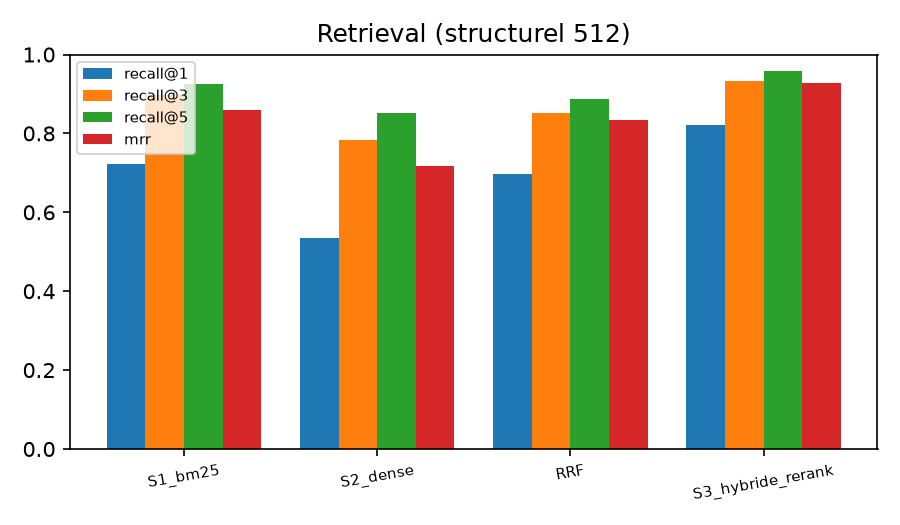

In [7]:
from IPython.display import Image
Image(ROOT / "figures/retrieval.png")

Lecture : le **reranker** apporte le gain principal (Recall@1 de 0,72 pour BM25 à 0,82 pour S3 ; MRR de 0,86 à 0,93). La fusion RRF seule n'améliore pas BM25 ; le dense seul est moins bon que BM25. Ces chiffres portent sur des questions **non relues**, générées par un LLM qui reprend souvent les mots du texte, ce qui **favorise BM25** (voir §9).

### 7.2 Effet du découpage sur BM25 et sur le dense (Recall@5)

In [8]:
import numpy as np
from src import retrieval_eval as R
from src.bm25 import BM25
from src.dense import DenseIndex
from src import dense as D
qs_ev = [q for q in qs if q["type"] != "sans_reponse"]
rows = []
for strat in ("fixed", "structural"):
    for size in (256, 512, 1024):
        name = f"{strat}_{size}"
        chs = R.load_chunks(name)
        bm = BM25([c["context"] + "\n" + c["text"] for c in chs])
        s1 = R.summarize(R.evaluate(lambda q, k: [i for i, _ in bm.search(q, k)], chs, qs))
        rows.append({"découpage": name, "BM25 R@5": round(s1["recall@5"], 3), "BM25 MRR": round(s1["mrr"], 3)})
pd.DataFrame(rows)

,découpage,BM25 R@5,BM25 MRR
0,fixed_256,0.848,0.773
1,fixed_512,0.875,0.846
2,fixed_1024,0.905,0.823
3,structural_256,0.864,0.819
4,structural_512,0.924,0.860
5,structural_1024,0.909,0.840


Avec le dense (calculé une fois, voir `src/dense.py`) : Recall@5 de 0,85 (structurel 512), 0,81 (structurel 256), 0,83 (structurel 1024), 0,75 (fixe 512), 0,83 (fixe 256), 0,75 (fixe 1024). **Le découpage structurel est meilleur que le fixe** dans les deux méthodes, nettement pour le dense à 512 et 1024 tokens.

### 7.3 Génération

In [9]:
gen_path = ROOT / "results/generations_provisoire.csv"
g = pd.read_csv(gen_path)
print(g.groupby("systeme").size().to_string())

systeme
S0          61
S1_bm25     61
S2_dense    14


In [10]:
pd.read_csv(ROOT / "results/metriques_par_systeme.csv")

,systeme,n_répondables,n_sans_réponse,correct (juge),F1,abstention correcte,refus injustifié,tokens/requête,latence (s),coût / 1000 req ($),fidélité (juge)
0,S0 sans retrieval,48,13,0.24 [0.16 ; 0.32],0.33 [0.28 ; 0.39],0.15 [0.00 ; 0.38],0.08,267,0.59,0.045,NaN
1,S1 BM25,48,13,0.78 [0.68 ; 0.88],0.58 [0.50 ; 0.66],0.77 [0.54 ; 1.00],0.10,2102,0.65,0.175,0.98 [0.95 ; 1.00]


      a  b  diff  ic_bas  ic_haut      verdict
S1_bm25 S0 0.542   0.406    0.677 significatif

         factuelle  multi  numerique
systeme                             
S0            0.30   0.06       0.23
S1_bm25       0.83   0.50       0.85


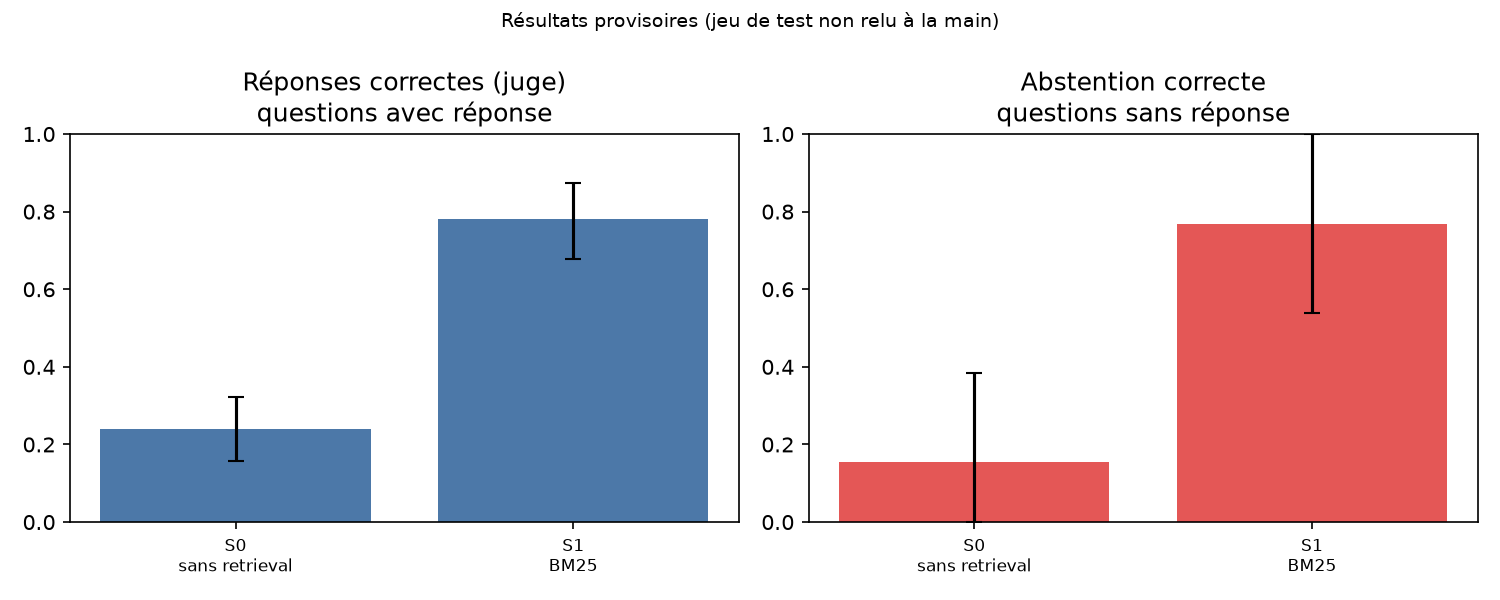

In [11]:
print(pd.read_csv(ROOT / "results/differences_bootstrap.csv").round(3).to_string(index=False))
print()
print(pd.read_csv(ROOT / "results/correct_par_type.csv", index_col=0).dropna(how="all").to_string())
Image(ROOT / "figures/resultats_generation.png")

**Résultats provisoires, S0 contre S1, 61 questions non relues** (S2 et S3 : génération non réalisée, quota journalier de l'API épuisé, voir §9) :
- Le **RAG est nettement meilleur que le LLM seul** : 78 % de réponses correctes avec BM25 contre 24 % sans documents ; la différence appariée (+0,54, IC95 % [0,41 ; 0,68]) est significative.
- Le LLM seul **n'ose presque jamais s'abstenir** quand la réponse n'existe pas dans le corpus : 15 % d'abstentions correctes (S0) contre 77 % avec les extraits (S1). Il invente donc des valeurs.
- La **fidélité** aux extraits est très élevée avec RAG (0,98) : quand le système répond, c'est presque toujours ce que disent les extraits.
- Les questions **multi-passages** sont les plus difficiles (50 % avec BM25 contre 83 à 85 % pour les autres types).
- Erreurs de S1 : « bon contexte mais réponse incomplète ou fausse » (8), refus injustifié (5), hallucination sur question sans réponse (3), passage non retrouvé (2).
- Coût : environ 2 100 tokens par requête RAG contre 270 sans documents, soit ~8 fois plus ; la latence reste inférieure à 1 s.

### 7.4 Validité du juge

In [12]:
from sklearn.metrics import cohen_kappa_score
a = pd.read_csv(ROOT / "results/annotations_claude.csv", sep=";", encoding="utf-8-sig")
j = pd.read_csv(ROOT / "results/_notes_juge_cachees.csv")
d = a.merge(j, on=["id", "systeme"])
h3, j3 = (d.claude_note * 2).astype(int), (d.correct_juge * 2).astype(int)
print(f"{len(d)} réponses | accord brut {np.mean(h3 == j3):.3f} | kappa {cohen_kappa_score(h3, j3):.3f} | kappa pondéré {cohen_kappa_score(h3, j3, weights='quadratic'):.3f}")
pd.crosstab(d.claude_note, d.correct_juge, rownames=["annotation (Claude)"], colnames=["juge"])

30 réponses | accord brut 0.967 | kappa 0.925 | kappa pondéré 0.967


juge,0.0,0.5,1.0
annotation (Claude),,,
0.0,4,0,0
0.5,0,4,1
1.0,0,0,21


Accord élevé (29/30), mais c'est un accord **entre deux LLM**, sur un échantillon facile (29 réponses de S1 sur 30), jugé par rapport à la référence seule : à ne pas surinterpréter.

## 8. Interprétation et analyse critique

**Ce que les résultats montrent (provisoires, jeu de test non relu).**

1. **Le RAG est indispensable.** Sans documents, le LLM répond correctement à 24 % des questions et ne s'abstient presque jamais quand la réponse n'existe pas (15 %) : il invente des valeurs précises et plausibles (ex. une « distance de sécurité de 0,5 m si la vitesse est ≤ 0,5 m/s », une « inspection annuelle »). Avec les extraits de BM25, il atteint 78 % de réponses correctes et 77 % d'abstentions correctes, et ses affirmations sont à 98 % soutenues par les extraits. L'écart (+0,54) est significatif au bootstrap. C'est le résultat principal : l'apport du retrieval est massif sur un domaine où les valeurs exactes comptent.
2. **Le reranker est la brique qui apporte le plus au retrieval** : Recall@1 de 0,72 (BM25) à 0,82 (S3), MRR de 0,86 à 0,93. La fusion RRF seule n'améliore pas BM25 (Recall@5 0,89 contre 0,92) : combiner deux classements dont l'un est nettement moins bon dilue le meilleur. Le gain vient de la relecture fine du couple question-passage, pas de la fusion.
3. **Le découpage structurel bat le découpage fixe**, nettement pour le dense (Recall@5 0,85 contre 0,75 à 512 tokens) : ne pas couper un article ou une section, et préfixer le fil d'Ariane, aide la recherche.
4. **BM25 bat le dense** (Recall@5 0,92 contre 0,85). Explication probable, à nuancer : le vocabulaire est très technique (sigles, normes, valeurs), et les questions, générées par un LLM à partir du texte, en **reprennent souvent les mots exacts**, ce qui avantage la recherche lexicale. Ce résultat ne dit pas que le dense est mauvais en général, mais que ce jeu de test le désavantage.
5. **Les questions multi-passages sont les plus difficiles** (50 % de réussite avec BM25, contre 83 à 85 % pour les factuelles et les numériques) : il faut retrouver *deux* passages dans le top 5.

**Analyse d'erreurs (S1, 61 questions).** 43 réponses correctes ; 8 « bon contexte mais réponse incomplète ou fausse » (le modèle omet un élément ou en ajoute un) ; 5 refus injustifiés (le modèle s'abstient alors que le passage est présent) ; 3 hallucinations sur des questions sans réponse ; 2 passages non retrouvés. Une partie des erreurs vient du jeu de test lui-même (références imprécises ou tautologiques, §9).

**Coût.** Un appel RAG consomme environ 2 100 tokens contre 270 sans documents (×8), pour une latence inférieure à la seconde. La qualité se paie en tokens, et c'est ce qui limite l'échelle des expériences avec un quota gratuit.

**Esprit critique.** Les intervalles de confiance sont larges (61 questions, 13 sans réponse) ; le juge est un LLM validé par un autre LLM ; les questions n'ont pas été relues. Les écarts très grands (S0 contre S1) sont robustes à ces défauts ; les petits écarts (par ex. S1 contre S3 en retrieval) devraient être confirmés avec le jeu relu.

## 9. Limites et perspectives

- **Jeu de test non relu à la main.** Les preuves sont vérifiées automatiquement, mais les questions et références n'ont pas toutes été validées par un humain. Certaines références sont défectueuses (par ex. une réponse tautologique, ou une catégorie « 3 » alors que le système répond « C2 »).
- **Biais du jeu de test** : questions générées par LLM à partir de chunks structurels 512, avec reprise du vocabulaire du texte : avantage probable pour BM25 et pour cette configuration.
- **Jeu réduit** : 61 questions pour la génération (contrainte de quota).
- **Quota Groq gratuit** (200 000 tokens/jour/modèle) : il a limité l'échelle de l'expérience. La génération n'a été terminée que pour **S0 et S1** ; **S2 et S3 ne sont évalués qu'en retrieval**. Le code de génération et de jugement est prêt (`src/run_generation.py`) et reprend là où il s'est arrêté grâce au cache.
- **Ablations non réalisées** : top-k, prompt simple contre prompt avec citations, HyDE, query rewriting, petit contre grand LLM.
- **Juge validé par un LLM, pas par un humain**, sur 30 réponses, sans seuil de confiance.
- **Corpus** dominé par l'INRS (38/40) ; figures et pictogrammes non extraits ; tableaux sur plusieurs pages parfois mal reconstitués.
- **Perspectives** : relecture complète du jeu de test, kappa humain, ablations (top-k, HyDE, query rewriting), petit contre grand LLM, fine-tuning léger des embeddings sur le vocabulaire du domaine.

## 10. Conclusion

Sur un corpus de 40 documents français sur la sécurité des machines, un pipeline RAG codé à la main :
- **réduit fortement les hallucinations** : réponses correctes 78 % avec RAG (BM25) contre 24 % sans, abstentions correctes 77 % contre 15 %, avec des affirmations soutenues par les extraits dans 98 % des cas ;
- est le plus performant en **recherche hybride avec reranker** (S3 : Recall@5 0,96, MRR 0,93, contre 0,92 et 0,86 pour BM25 et 0,85 et 0,72 pour le dense) ;
- bénéficie d'un **découpage respectant la structure** des documents.

**Périmètre honnête** : la génération complète n'a été réalisée que pour S0 et S1 (61 questions) ; S2 et S3 ne sont évalués qu'en retrieval, faute de quota d'API. Le jeu de test n'a pas été relu intégralement à la main, et le juge a été validé par un autre LLM. Ces résultats sont donc des **résultats préliminaires solides sur les grands écarts**, et la conclusion S3 > S1 en génération reste à confirmer.

## 11. Références et source du dataset

**Dataset** : brochures INRS (inrs.fr), Règlement (UE) 2023/1230 et Directive 2006/42/CE (EUR-Lex). Liste complète, avec URL de chaque document : `data/sources.csv`.

**Références**
- Lewis et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*. NeurIPS.
- Robertson & Zaragoza (2009). *The Probabilistic Relevance Framework: BM25 and Beyond*.
- Chen et al. (2024). *BGE M3-Embedding: Multi-Lingual, Multi-Functionality, Multi-Granularity Text Embeddings*.
- Cormack, Clarke & Büttcher (2009). *Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods*. SIGIR.
- Zheng et al. (2023). *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena*. NeurIPS.
- Cohen (1960). *A coefficient of agreement for nominal scales*.